In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import time
from tensorflow.keras.applications import MobileNetV2
from scipy.linalg import sqrtm
from tensorflow.keras import layers
import glob
import imageio
import os
import PIL
import time
from IPython import display
import keras_tuner as kt

In [ ]:
pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 11.6 MB/s eta 0:00:00


In [ ]:
(train_images, train_labels), (_, _) = tf.keras.datasets.mnist.load_data()

train_images = train_images.reshape(train_images.shape[0], 28, 28, 1).astype('float32')
train_images = (train_images - 127.5) / 127.5  # Normalize the images to [-1, 1]

BUFFER_SIZE = 60000
batch_size = 256

train_dataset = tf.data.Dataset.from_tensor_slices(train_images).shuffle(BUFFER_SIZE).batch(batch_size)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


## Base Model

In [ ]:
# Generator
def base_generator_model():
    model = tf.keras.Sequential()
    # 100 random values will be input, connected densely to 7*7*256 nodes
    model.add(layers.Dense(7*7*256, use_bias=False, input_shape=(100,)))
    model.add(layers.BatchNormalization())  # centers & scales parameters--reduces overfitting
    model.add(layers.LeakyReLU())
    model.add(layers.Reshape((7, 7, 256)))  # https://www.tensorflow.org/api_docs/python/tf/reshape
    assert model.output_shape == (None, 7, 7, 256)  # None is the batch size
    # padding='same' ensures output has same dimensions as input
    model.add(layers.Conv2DTranspose(128, (5, 5), strides=(1, 1),
                                     padding='same', use_bias=False))
    assert model.output_shape == (None, 7, 7, 128)
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())
    model.add(layers.Conv2DTranspose(64, (5, 5), strides=(2, 2),
                                     padding='same', use_bias=False))
    assert model.output_shape == (None, 14, 14, 64)
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())
    model.add(layers.Conv2DTranspose(1, (5, 5), strides=(2, 2),
                                     padding='same', use_bias=False, activation='tanh'))
    assert model.output_shape == (None, 28, 28, 1)  # MNIST dimensions
    return model

generator = base_generator_model()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Discriminator
def base_discriminator_model():
    model = tf.keras.Sequential()
    model.add(layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same',
                                     input_shape=[28, 28, 1]))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1))

    return model

discriminator = base_discriminator_model()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


tf.Tensor([[-0.00203042]], shape=(1, 1), dtype=float32)


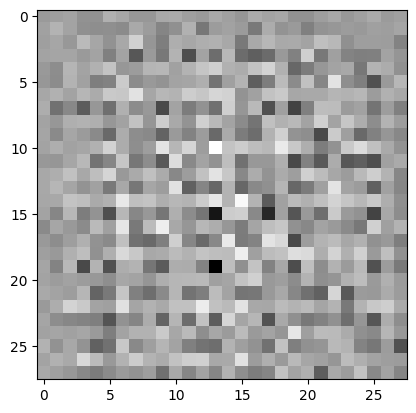

In [ ]:
noise = tf.random.normal([1, 100])
generated_image = generator(noise, training=False)

plt.imshow(generated_image[0, :, :, 0], cmap='gray')
decision = discriminator(generated_image)
print (decision)

In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)
# Generator Loss
def discriminator_loss(real_output, fake_output):
    # real_output should be 1 and fake output 0
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    total_loss = real_loss + fake_loss
    return total_loss

# Discriminator Loss
def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

In [ ]:
checkpoint_dir = './training_checkpoints'
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(generator_optimizer=generator_optimizer,
                                 discriminator_optimizer=discriminator_optimizer,
                                 generator=generator,
                                 discriminator=discriminator)

In [ ]:
EPOCHS = 50
noise_dim = 100
num_examples = 16

seed = tf.random.normal([num_examples, noise_dim])

In [ ]:
@tf.function
def train_step(real_images):
    # Generate random latent vectors (noise) of shape (BATCH_SIZE, 100)
    noise = tf.random.normal([BATCH_SIZE, 100])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        # Pass latent vectors (random noise) to the Generator to create fake images
        generated_images = generator(noise, training=True)

        # Get the Discriminator's output for real images and generated (fake) images
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(generated_images, training=True)

        # Calculate the Generator's loss (based on Discriminator's output for fake images)
        gen_loss = generator_loss(fake_output)

        # Calculate the Discriminator's loss (based on Discriminator's output for real and fake images)
        disc_loss = discriminator_loss(real_output, fake_output)

    # Get the gradients of the loss with respect to the trainable variables
    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    # Apply the gradients to the optimizers
    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

def train(dataset, epochs):
  for epoch in range(epochs):
    start = time.time()

    for image_batch in dataset:
      train_step(image_batch)

    # Produce images for the GIF
    display.clear_output(wait=True)
    generate_and_save_images(generator,
                             epoch + 1,
                             seed)

    # Save the model every 15 epochs
    if (epoch + 1) % 15 == 0:
      checkpoint.save(file_prefix = checkpoint_prefix)

    print ('Time for epoch {} is {} sec'.format(epoch + 1, time.time()-start))

  # Generate after the final epoch
  display.clear_output(wait=True)
  generate_and_save_images(generator,
                           epochs,
                           seed)

def generate_and_save_images(model, epoch, test_input):
  # Notice `training` is set to False.
  # This is so all layers run in inference mode (batchnorm).
  predictions = model(test_input, training=False)

  fig = plt.figure(figsize=(4, 4))

  for i in range(predictions.shape[0]):
      plt.subplot(4, 4, i+1)
      plt.imshow(predictions[i, :, :, 0] * 127.5 + 127.5, cmap='gray')
      plt.axis('off')

  plt.savefig('image_at_epoch_{:04d}.png'.format(epoch))
  plt.show()

## Base Model Training

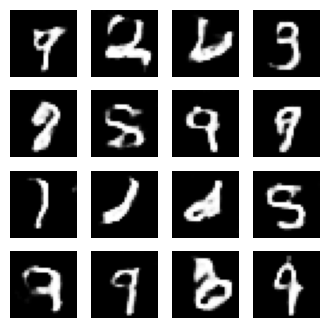

In [ ]:
train(train_dataset, EPOCHS)

## Evaluation Metrics: Inception Score & Frechet Inception Distance

In [ ]:
real_images = train_images[np.random.choice(train_images.shape[0], 1000, replace=False)]

In [ ]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.applications import MobileNetV2
from scipy.linalg import sqrtm

def calculate_inception_score(images, n_splits=10):
    images = (images * 127.5 + 127.5)  # Rescale images from [-1, 1] to [0, 255]
    if images.shape[-1] == 1:     # Ensure images have 3 channels
        images = tf.image.grayscale_to_rgb(images)
    images_resized = tf.image.resize(images, (32, 32)) # Resize images to MobileNetV2 input size (32x32)
    images_resized = images_resized.numpy()
    images_preprocessed = tf.keras.applications.mobilenet_v2.preprocess_input(images_resized)

    model = MobileNetV2(include_top=False, pooling='avg', input_shape=(32, 32, 3))
    # Get predictions
    preds = model.predict(images_preprocessed, verbose=0)
    # Clip predictions to avoid zero probabilities
    preds = np.clip(preds, 1e-10, 1.0)
    # Compute Inception Score
    scores = []
    for i in range(n_splits):
        part = preds[i * len(preds) // n_splits:(i + 1) * len(preds) // n_splits]
        py = np.mean(part, axis=0)
        py = np.clip(py, 1e-10, None)  # Avoid division by zero
        kl_div = np.sum(part * np.log(part / py), axis=1)
        scores.append(np.exp(np.mean(kl_div)))
    return np.mean(scores), np.std(scores)


def calculate_fid(real_images, generated_images):
    real_images = (real_images * 127.5 + 127.5)
    generated_images = (generated_images * 127.5 + 127.5)
    if real_images.shape[-1] == 1:   # Ensure images have 3 channels
        real_images = tf.image.grayscale_to_rgb(real_images)
    if generated_images.shape[-1] == 1:
        generated_images = tf.image.grayscale_to_rgb(generated_images)
    # Resize images to MobileNetV2 input size (32x32)
    real_images_resized = tf.image.resize(real_images, (32, 32))
    generated_images_resized = tf.image.resize(generated_images, (32, 32))
    real_images_resized = real_images_resized.numpy()
    generated_images_resized = generated_images_resized.numpy()
    real_images_preprocessed = tf.keras.applications.mobilenet_v2.preprocess_input(real_images_resized)
    generated_images_preprocessed = tf.keras.applications.mobilenet_v2.preprocess_input(generated_images_resized)

    # Load MobileNetV2 model
    model = MobileNetV2(include_top=False, pooling='avg', input_shape=(32, 32, 3))
    # Extract features
    real_features = model.predict(real_images_preprocessed, verbose=0)
    generated_features = model.predict(generated_images_preprocessed, verbose=0)
    # Compute mean and covariance
    mu_real, sigma_real = real_features.mean(axis=0), np.cov(real_features, rowvar=False)
    mu_generated, sigma_generated = generated_features.mean(axis=0), np.cov(generated_features, rowvar=False)
    # Add small value to diagonal for numerical stability
    epsilon = 1e-6
    sigma_real += np.eye(sigma_real.shape[0]) * epsilon
    sigma_generated += np.eye(sigma_generated.shape[0]) * epsilon
    # Compute FID
    diff = mu_real - mu_generated
    covmean, _ = sqrtm(sigma_real @ sigma_generated, disp=False)
    # Handle numerical errors
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = diff @ diff + np.trace(sigma_real + sigma_generated - 2.0 * covmean)
    return fid

In [ ]:
# Calculate IS
mean_is, std_is = calculate_inception_score(generated_images)
print(f"Inception Score: Mean = {mean_is}, Std = {std_is}")

# Calculate FID
fid_score = calculate_fid(real_images, generated_images)
print(f"FID Score: {fid_score}")

<ipython-input-96-c4ddcdf88f4d>:20: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  model = MobileNetV2(include_top=False, pooling='avg', input_shape=(32, 32, 3))


Inception Score: Mean = 4.761201858520508, Std = 5.709187984466553


<ipython-input-98-39cea8ab2a33>:30: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  model = MobileNetV2(include_top=False, pooling='avg', input_shape=(32, 32, 3))


FID Score: 95.38227996512259


## Hyperparameter Tuning

In [ ]:
# Define the GAN class
class GAN(tf.keras.Model):
    def __init__(self, discriminator, generator, latent_dim):
        super(GAN, self).__init__()
        self.discriminator = discriminator
        self.generator = generator
        self.latent_dim = latent_dim

    def compile(self, d_optimizer, g_optimizer, loss_fn):
        super(GAN, self).compile()
        self.d_optimizer = d_optimizer
        self.g_optimizer = g_optimizer
        self.loss_fn = loss_fn

    def train_step(self, data):
        # Unpack the data
        real_images = data
        # Sample random points in the latent space
        batch_size = tf.shape(real_images)[0]
        random_latent_vectors = tf.random.normal(shape=(batch_size, self.latent_dim))
        # Generate fake images
        generated_images = self.generator(random_latent_vectors)
        # Combine real and fake images
        combined_images = tf.concat([real_images, generated_images], axis=0)
        # Assemble labels for real and fake images
        labels = tf.concat(
            [tf.ones((batch_size, 1)), tf.zeros((batch_size, 1))], axis=0
        )
        # Train the discriminator
        with tf.GradientTape() as tape:
            predictions = self.discriminator(combined_images)
            d_loss = self.loss_fn(labels, predictions)
        grads = tape.gradient(d_loss, self.discriminator.trainable_weights)
        self.d_optimizer.apply_gradients(zip(grads, self.discriminator.trainable_weights))
        # Generate misleading labels for generator training
        misleading_labels = tf.ones((batch_size, 1))
        # Train the generator
        with tf.GradientTape() as tape:
            predictions = self.discriminator(self.generator(random_latent_vectors))
            g_loss = self.loss_fn(misleading_labels, predictions)
        grads = tape.gradient(g_loss, self.generator.trainable_weights)
        self.g_optimizer.apply_gradients(zip(grads, self.generator.trainable_weights))
        return {"d_loss": d_loss, "g_loss": g_loss}

In [ ]:
# Tuning filters and dropout rates
class HyperGAN_filters(kt.HyperModel):
    def __init__(self, real_images):
        self.real_images = real_images

    def make_discriminator_model(self, hp):
        model = tf.keras.Sequential()
        model.add(
            layers.Conv2D(
                hp.Choice("disc_filters_1", values=[64, 128, 256]),
                (5, 5),
                strides=(2, 2),
                padding="same",
                input_shape=[28, 28, 1],
            )
        )
        model.add(layers.LeakyReLU())
        model.add(layers.Dropout(hp.Choice("dropout_1", values=[0.0, 0.1, 0.2, 0.3])))

        model.add(
            layers.Conv2D(
                hp.Choice("disc_filters_2", values=[128, 256, 512]),
                (5, 5),
                strides=(2, 2),
                padding="same",
            )
        )
        model.add(layers.LeakyReLU())
        model.add(layers.Dropout(hp.Choice("dropout_2", values=[0.0, 0.1, 0.2, 0.3])))
        model.add(layers.Flatten())
        model.add(layers.Dense(1))
        return model

    def make_generator_model(self, hp):
        model = tf.keras.Sequential()
        # Dense and Reshape layer
        model.add(
            layers.Dense(
                7 * 7 * hp.Choice("gen_filters_1", values=[128, 256, 512]),
                use_bias=False,
                input_shape=(100,),))
        model.add(layers.BatchNormalization())
        model.add(layers.LeakyReLU())
        model.add(layers.Reshape((7, 7, hp.Choice("gen_filters_1", values=[128, 256, 512]))))
        # First Conv2DTranspose layer
        model.add(
            layers.Conv2DTranspose(
                hp.Choice("gen_filters_2", values=[64, 128, 256]),
                (5, 5), strides=(1, 1), padding="same", use_bias=False))
        model.add(layers.BatchNormalization())
        model.add(layers.LeakyReLU())
        # Second Conv2DTranspose layer
        model.add(
            layers.Conv2DTranspose(
                hp.Choice("gen_filters_3", values=[32, 64, 128]),
                (5, 5), strides=(2, 2), padding="same", use_bias=False))
        model.add(layers.BatchNormalization())
        model.add(layers.LeakyReLU())
        # Final Conv2DTranspose layer for output
        model.add(
            layers.Conv2DTranspose(1,(5, 5),
                strides=(2, 2), padding="same", activation="tanh"))
        return model

    def build(self, hp):
        discriminator = self.make_discriminator_model(hp)
        generator = self.make_generator_model(hp)
        gan = GAN(discriminator, generator, latent_dim=100)
        gan.compile(
            d_optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
            g_optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
            loss_fn=tf.keras.losses.BinaryCrossentropy(from_logits=True),
        )
        return gan

    def fit(self, hp, model, x, **kwargs):
        history = model.fit(x, **kwargs)
        d_loss = history.history["d_loss"][-1]
        # Convert to float if it's a TensorFlow tensor
        if isinstance(d_loss, tf.Tensor):
            d_loss = float(d_loss.numpy())
        return d_loss

tuner = kt.BayesianOptimization(
    hypermodel=HyperGAN_filters(),
    objective=kt.Objective("d_loss", direction="min"),
    max_trials=30,
    directory="gan_tuning_1",
    project_name="hyper_gan",
)

tuner.search(train_images, epochs=20, batch_size=32)

best_trial = tuner.oracle.get_best_trials(num_trials=1)[0]

print("Best Trial:")
print(f"Hyperparameters: {best_trial.hyperparameters.values}")
print(f"Best d_loss: {best_trial.score}")

Trial 30 Complete [00h 00m 19s]
d_loss: 0.0004975312622264028

Best d_loss So Far: 9.489466901868582e-05
Total elapsed time: 00h 09m 46s
Best Trial:
Hyperparameters: {'disc_filters_1': 256, 'dropout_1': 0.1, 'disc_filters_2': 512, 'dropout_2': 0.0, 'gen_filters_1': 512, 'gen_filters_2': 256, 'gen_filters_3': 64}
Best d_loss: 9.489466901868582e-05


**Comment**: Since the filter number cap is reached in several layers for both generator and discriminator, additional Conv2DTranspose layer and Conv2D layer is added to generator and discriminator to test performance

In [ ]:
# Adding additional layer
class HyperGAN_additional_layer(kt.HyperModel):
    def make_discriminator_model(self, hp):
        model = tf.keras.Sequential()
        # First Conv2D Layer
        model.add(
            layers.Conv2D(
                filters=hp.Choice("disc_filters_1", values=[64, 128, 256]),
                kernel_size=(5, 5),
                strides=(2, 2),
                padding="same",
                input_shape=(28, 28, 1)
            )
        )
        model.add(layers.LeakyReLU())
        model.add(layers.Dropout(hp.Choice("dropout_1", values=[0.0, 0.1, 0.2, 0.3])))
        # Second Conv2D Layer
        model.add(
            layers.Conv2D(
                filters=hp.Choice("disc_filters_2", values=[128, 256, 512]),
                kernel_size=(5, 5),
                strides=(2, 2),
                padding="same"
            )
        )
        model.add(layers.LeakyReLU())
        model.add(layers.Dropout(hp.Choice("dropout_2", values=[0.0, 0.1, 0.2, 0.3])))
        # Additional Conv2D Layer
        model.add(
            layers.Conv2D(
                filters=hp.Choice("disc_filters_3", values=[64, 128, 256]),
                kernel_size=(5, 5),
                strides=(1, 1),
                padding="same"
            )
        )
        model.add(layers.LeakyReLU())
        model.add(layers.Dropout(hp.Choice("dropout_3", values=[0.0, 0.1, 0.2, 0.3])))
        model.add(layers.Flatten())
        model.add(layers.Dense(1))
        return model

    def make_generator_model(self, hp):
        model = tf.keras.Sequential()
        latent_dim = 100
        # Dense and Reshape layers
        model.add(
            layers.Dense(7 * 7 * hp.Choice("gen_filters_1", values=[128, 256, 512]),
                         use_bias=False, input_shape=(latent_dim,))
        )
        model.add(layers.BatchNormalization())
        model.add(layers.LeakyReLU())
        model.add(layers.Reshape((7, 7, hp.Choice("gen_filters_1", values=[128, 256, 512]))))
        # First Conv2DTranspose Layer
        model.add(
            layers.Conv2DTranspose(
                filters=hp.Choice("gen_filters_2", values=[128, 256]),
                kernel_size=(5, 5),
                strides=(1, 1),
                padding="same",
                use_bias=False
            )
        )
        model.add(layers.BatchNormalization())
        model.add(layers.LeakyReLU())
        # Second Conv2DTranspose Layer
        model.add(
            layers.Conv2DTranspose(
                filters=hp.Choice("gen_filters_3", values=[64, 128, 256]),
                kernel_size=(5, 5),
                strides=(2, 2),
                padding="same",
                use_bias=False
            )
        )
        model.add(layers.BatchNormalization())
        model.add(layers.LeakyReLU())
        # Third Conv2DTranspose Layer
        model.add(
            layers.Conv2DTranspose(
                filters=hp.Choice("gen_filters_4", values=[32, 64, 128]),
                kernel_size=(5, 5),
                strides=(2, 2),
                padding="same",
                use_bias=False
            )
        )
        model.add(layers.BatchNormalization())
        model.add(layers.LeakyReLU())
        # Final Conv2DTranspose Layer
        model.add(
            layers.Conv2DTranspose(
                filters=1,
                kernel_size=(5, 5),
                strides=(1, 1),
                padding="same",
                activation="tanh"
            )
        )
        return model

    def build(self, hp):
        discriminator = self.make_discriminator_model(hp)
        generator = self.make_generator_model(hp)
        gan = GAN(discriminator, generator, latent_dim=100)
        gan.compile(
            d_optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
            g_optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
            loss_fn=tf.keras.losses.BinaryCrossentropy(from_logits=False),
        )
        return gan

    def fit(self, hp, model, x, **kwargs):
        history = model.fit(x, **kwargs)
        d_loss = history.history["d_loss"][-1]
        return float(d_loss)
\
tuner = kt.BayesianOptimization(
    hypermodel=HyperGAN_additional_layer(),
    objective=kt.Objective("d_loss", direction="min"),
    max_trials=20,
    directory="gan_tune_2",
    project_name="hyper_gan",
)

tuner.search(train_images, epochs=20, batch_size=32)

best_trial = tuner.oracle.get_best_trials(num_trials=1)[0]

print("Best Trial:")
print(f"Hyperparameters: {best_trial.hyperparameters.values}")
print(f"Best d_loss: {best_trial.score}")

Trial 20 Complete [00h 00m 21s]
d_loss: 0.0003984812065027654

Best d_loss So Far: 7.243715663207695e-05
Total elapsed time: 00h 06m 48s
Best Trial:
Hyperparameters: {'disc_filters_1': 128, 'dropout_1': 0.0, 'disc_filters_2': 512, 'dropout_2': 0.2, 'disc_filters_3': 256, 'dropout_3': 0.0, 'gen_filters_1': 256, 'gen_filters_2': 128, 'gen_filters_3': 256, 'gen_filters_4': 32}
Best d_loss: 7.243715663207695e-05


**Comment**: Since the resulting d_loss is lower, the additional layers are adopted

In [ ]:
# Tuning kernel sizes
class HyperGAN_kernel(kt.HyperModel):
    def make_discriminator_model(self, hp):
        model = tf.keras.Sequential([
            layers.Conv2D(128,
                kernel_size=hp.Choice("disc_kernel_1", values=[3, 5, 7]),
                strides=(2, 2),
                padding="same",
                input_shape=(28, 28, 1)),
            layers.LeakyReLU(),
            layers.Conv2D(512,
                kernel_size=hp.Choice("disc_kernel_2", values=[3, 5, 7]),
                strides=(2, 2),
                padding="same"),
            layers.LeakyReLU(),
            layers.Dropout(0.2),
            layers.Conv2D(256,
                kernel_size=hp.Choice("disc_kernel_3", values=[3, 5, 7]),
                strides=(1, 1),
                padding="same"),
            layers.LeakyReLU(),
            layers.Flatten(),
            layers.Dense(1)
        ])
        return model

    def make_generator_model(self, hp):
        model = tf.keras.Sequential([
            layers.Dense(7 * 7 * 256, use_bias=False, input_shape=(100,)),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Reshape((7, 7, 256)),

            layers.Conv2DTranspose(128,
                kernel_size=hp.Choice("gen_kernel_1", values=[3, 5, 7]),
                strides=(1, 1),
                padding="same",
                use_bias=False),
            layers.BatchNormalization(),
            layers.LeakyReLU(),

            layers.Conv2DTranspose(256,
                kernel_size=hp.Choice("gen_kernel_2", values=[3, 5, 7]),
                strides=(2, 2),
                padding="same",
                use_bias=False),
            layers.BatchNormalization(),
            layers.LeakyReLU(),

            layers.Conv2DTranspose(32,
                kernel_size=hp.Choice("gen_kernel_3", values=[3, 5, 7]),
                strides=(2, 2),
                padding="same",
                use_bias=False),
            layers.BatchNormalization(),
            layers.LeakyReLU(),

            layers.Conv2DTranspose(1,
                kernel_size=hp.Choice("gen_kernel_4", values=[3, 5, 7]),
                strides=(1, 1),
                padding="same",
                activation="tanh")
        ])
        return model

    def build(self, hp):
        discriminator = self.make_discriminator_model(hp)
        generator = self.make_generator_model(hp)
        gan = GAN(discriminator, generator, latent_dim=100)

        gan.compile(
            d_optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
            g_optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
            loss_fn=tf.keras.losses.BinaryCrossentropy(from_logits=False),
        )
        return gan

    def fit(self, hp, model, x, **kwargs):
        history = model.fit(x, **kwargs)
        d_loss = history.history["d_loss"][-1]
        return float(d_loss)

tuner = kt.BayesianOptimization(
    hypermodel=HyperGAN_kernel(),
    objective=kt.Objective("d_loss", direction="min"),
    max_trials=30,
    directory="gan_tune_kernel",
    project_name="tune_kernel_size"
)

tuner.search(train_images, epochs=20, batch_size=32)

best_trial = tuner.oracle.get_best_trials(num_trials=1)[0]

print("Best Trial:")
print(f"Hyperparameters: {best_trial.hyperparameters.values}")
print(f"Best d_loss: {best_trial.score}")

Trial 30 Complete [00h 00m 31s]
d_loss: 0.00023348788090515882

Best d_loss So Far: 2.5749526685103774e-05
Total elapsed time: 00h 13m 17s
Best Trial:
Hyperparameters: {'disc_kernel_1': 5, 'disc_kernel_2': 7, 'disc_kernel_3': 5, 'gen_kernel_1': 3, 'gen_kernel_2': 7, 'gen_kernel_3': 5, 'gen_kernel_4': 5}
Best d_loss: 2.5749526685103774e-05


**Comment**: There is an improvement in the d_loss, therefore this hyperparameter is adopted

In [ ]:
class HyperGAN_lr_bs(kt.HyperModel):
    def __init__(self):
        super(HyperGAN_lr_bs, self).__init__()

    def make_discriminator_model(self):
        model = tf.keras.Sequential([
            layers.Conv2D(128, (5, 5), strides=(2, 2), padding="same", input_shape=(28, 28, 1)),
            layers.LeakyReLU(),
            layers.Conv2D(512, (7, 7), strides=(2, 2), padding="same"),
            layers.LeakyReLU(),
            layers.Dropout(0.2),
            layers.Conv2D(256, (5, 5), strides=(1, 1), padding="same"),
            layers.LeakyReLU(),
            layers.Flatten(),
            layers.Dense(1, activation="sigmoid"),
        ])
        return model

    def make_generator_model(self):
        model = tf.keras.Sequential([
            layers.Dense(7 * 7 * 256, use_bias=False, input_shape=(100,)),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Reshape((7, 7, 256)),
            layers.Conv2DTranspose(128, (3, 3), strides=(1, 1), padding="same", use_bias=False),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Conv2DTranspose(256, (7, 7), strides=(2, 2), padding="same", use_bias=False),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Conv2DTranspose(32, (5, 5), strides=(2, 2), padding="same", use_bias=False),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Conv2DTranspose(1, (5, 5), strides=(1, 1), padding="same", activation="tanh"),
        ])
        return model

    def build(self, hp):
        discriminator = self.make_discriminator_model()
        generator = self.make_generator_model()

        gan = GAN(discriminator, generator, latent_dim=100)
        d_lr = hp.Choice("d_lr", values=[1e-5, 5e-5, 1e-4, 5e-4])
        g_lr = hp.Choice("g_lr", values=[1e-5, 5e-5, 1e-4, 5e-4])
        batch_size = hp.Choice("batch_size", values=[16, 32, 64])
        self.batch_size = batch_size  # Save batch size for dataset preparation

        gan.compile(
            d_optimizer=tf.keras.optimizers.Adam(learning_rate=d_lr),
            g_optimizer=tf.keras.optimizers.Adam(learning_rate=g_lr),
            loss_fn=tf.keras.losses.BinaryCrossentropy(from_logits=False),
        )
        return gan

    def fit(self, hp, model, x, **kwargs):
        # Dynamically prepare the dataset with the tuner's batch size
        batch_size = hp.get("batch_size")
        dataset = tf.data.Dataset.from_tensor_slices(x).shuffle(60000).batch(batch_size)
        # Train the model and return the discriminator loss
        history = model.fit(dataset, **kwargs)
        return float(history.history["d_loss"][-1])

tuner = kt.BayesianOptimization(
    hypermodel=HyperGAN_lr_bs(),
    objective=kt.Objective("d_loss", direction="min"),
    max_trials=20,
    directory="tuning_lr_bs",
    project_name="hyper_gan_lr_bs",
)

tuner.search(train_images, epochs=10)

best_trial = tuner.oracle.get_best_trials(num_trials=1)[0]
print("Best Trial:")
print(f"Hyperparameters: {best_trial.hyperparameters.values}")
print(f"Best d_loss: {best_trial.score}")

Trial 20 Complete [00h 03m 23s]
d_loss: 1.0739127469239218e-11

Best d_loss So Far: 0.0
Total elapsed time: 00h 52m 14s
Best Trial:
Hyperparameters: {'d_lr': 0.0005, 'g_lr': 0.0005, 'batch_size': 16}
Best d_loss: 0.0


**Comment**: Since there is improvement on the d_loss, this hyperparameter is adopted

**Comment**: There is improvement in the d_loss, which is so close to zero, therefore this tuning is  adopted

## Testing Tuned Model

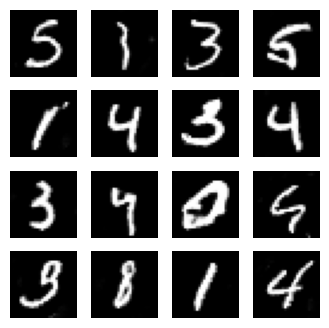

Time for epoch 50 is 29.11 sec


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import os
import time
import matplotlib.pyplot as plt

# Hyperparameters
LATENT_DIM = 100
BATCH_SIZE = 16
EPOCHS = 50
SEED_SIZE = 16  # num example
seed = tf.random.normal([SEED_SIZE, LATENT_DIM])
BUFFER_SIZE = 60000


# Load and preprocess data
(train_images, _), (_, _) = tf.keras.datasets.mnist.load_data()
train_images = train_images.reshape(train_images.shape[0], 28, 28, 1).astype("float32")
train_images = (train_images - 127.5) / 127.5  # Normalize to [-1, 1]
train_dataset = tf.data.Dataset.from_tensor_slices(train_images).shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

# the final Discriminator
def make_tuned_discriminator():
    model = tf.keras.Sequential([
        layers.Conv2D(128, (5, 5), strides=(2, 2), padding="same", input_shape=(28, 28, 1)),
        layers.LeakyReLU(),
        layers.Conv2D(512, (7, 7), strides=(2, 2), padding="same"),
        layers.LeakyReLU(),
        layers.Dropout(0.2),
        layers.Conv2D(256, (5, 5), strides=(1, 1), padding="same"),
        layers.LeakyReLU(),
        layers.Flatten(),
        layers.Dense(1, activation="sigmoid"),
    ])
    return model

# the final Generator
def make_tuned_generator(latent_dim):
    model = tf.keras.Sequential([
        layers.Dense(7 * 7 * 256, use_bias=False, input_shape=(latent_dim,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Reshape((7, 7, 256)),

        layers.Conv2DTranspose(128, (3, 3), strides=(1, 1), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(256, (7, 7), strides=(2, 2), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(32, (5, 5), strides=(2, 2), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(1, (5, 5), strides=(1, 1), padding="same", activation="tanh"),
    ])
    return model

generator = make_tuned_generator(LATENT_DIM)
discriminator = make_tuned_discriminator()

# optimizers
generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005)

# loss functions
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

# Training step
@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, LATENT_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss, real_output, fake_output

# Training loop
def train(dataset, epochs):
    for epoch in range(epochs):
        start = time.time()

        for image_batch in dataset:
            real_output, fake_output, gen_loss, disc_loss = train_step(image_batch)
        display.clear_output(wait=True)
        generate_and_save_images(generator, epoch + 1, seed)
        print(f"Time for epoch {epoch + 1} is {time.time() - start:.2f} sec")

def generate_and_save_images(model, epoch, test_input):
    predictions = model(test_input, training=False)

    fig = plt.figure(figsize=(4, 4))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i + 1)
        plt.imshow(predictions[i, :, :, 0] * 127.5 + 127.5, cmap="gray")
        plt.axis("off")
    plt.savefig(f"image_at_epoch_{epoch:04d}.png")
    plt.show()

train(train_dataset, EPOCHS)

In [ ]:
noise = tf.random.normal([100, LATENT_DIM])
generated_images = generator(noise, training=False)
real_images_sample = next(iter(train_dataset))[:100]

# Calculate Inception Score
mean_is, std_is = calculate_inception_score(generated_images)
print(f"Inception Score: Mean = {mean_is:.3f}, Std = {std_is:.3f}")

# Calculate FID Score
fid_score = calculate_fid(real_images_sample, generated_images)
print(f"FID Score: {fid_score:.3f}")

<ipython-input-12-6a9c8cd6feeb>:14: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  model = MobileNetV2(include_top=False, pooling='avg', input_shape=(32, 32, 3))


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Inception Score: Mean = 440.546, Std = 436.439


<ipython-input-12-6a9c8cd6feeb>:46: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  model = MobileNetV2(include_top=False, pooling='avg', input_shape=(32, 32, 3))


FID Score: 6.138


##  GIF Visualization

In [ ]:
# Specify the output GIF filename
anim_file = 'dcgan.gif'

# Create the GIF
with imageio.get_writer(anim_file, mode='I', duration=0.2, loop=0) as writer:
    filenames = sorted(glob.glob('image_at_epoch_*.png'))
    for filename in filenames:
        image = imageio.imread(filename)
        writer.append_data(image)

<ipython-input-14-1f3d3aeb126d>:8: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(filename)


In [ ]:
from google.colab import files
files.download('dcgan.gif')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install tensorflow_docs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 182.5/182.5 kB 12.9 MB/s eta 0:00:00



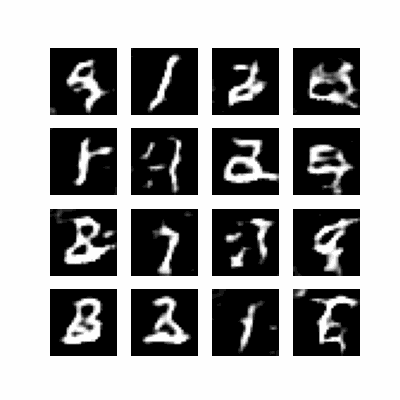

In [ ]:
import tensorflow_docs.vis.embed as embed
embed.embed_file(anim_file)